<a href="https://colab.research.google.com/github/vladijarosz/Cuenta-inv/blob/main/retornos_mensuales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [290]:
import pandas as pd
import re
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pyxirr import xirr, xnpv
from scipy.stats import gmean

In [291]:
mep= pd.read_csv("C:\\Users\\Admin\\Desktop\\Square Analytics\\finanzas\\2025\\DOLAR MEP - Cotizaciones historicas.csv")
mep["fecha"] = pd.to_datetime(mep["fecha"])



In [292]:
import pandas as pd
import glob, os, re

def cargar_reportes(carpeta):
    archivos = sorted(glob.glob(os.path.join(carpeta, "portfolio_report_*.csv")))
    dfs = []

    for ruta in archivos:
        df = pd.read_csv(ruta, sep=None, engine="python", decimal=",")
        fecha = re.search(r"(\d{8})", os.path.basename(ruta)).group(1)
        df["fecha_reporte"] = pd.to_datetime(fecha, format="%Y%m%d")
        dfs.append(df)

    return pd.concat(dfs, ignore_index=True)

cartera = cargar_reportes(r"C:\Users\Admin\Desktop\Square Analytics\finanzas\2025")
cartera['fecha']=cartera['fecha_reporte']

In [293]:


# ambas fechas como datetime y ordenadas (merge_asof lo exige)
cartera["fecha"] = pd.to_datetime(cartera["fecha"])
mep["fecha"]     = pd.to_datetime(mep["fecha"])

cartera = cartera.sort_values("fecha")
mep      = mep.sort_values("fecha")

cartera = pd.merge_asof(
    cartera, mep[["fecha", "cierre"]],
    on="fecha",
    direction="backward",              # el último MEP <= fecha del reporte
    tolerance=pd.Timedelta(days=5),    # pero no más de 5 días viejo
).rename(columns={"cierre": "mep"})

cartera["tot_pesos"] = np.where(
    cartera["moneda"] == "USD",
    cartera["total"]* cartera["mep"],
    cartera["total"] ,
)

cartera["tot_usd"] = np.where(
    cartera["moneda"] == "ARS",
    cartera["total"]/ cartera["mep"],
    cartera["total"],
)
cartera

,instrumento,cantidad,precio,moneda,total,fecha_reporte,fecha,mep,tot_pesos,tot_usd
0,CEDEAR ISHARES MSCI BRAZIL CAP (EWZ),483.00,15050.0,ARS,7269150.00,2025-01-31,2025-01-31,1164.79,7.269150e+06,6240.738674
1,USD,0.19,1.0,USD,0.19,2025-01-31,2025-01-31,1164.79,2.213101e+02,0.190000
2,EXT,3194.78,1.0,EXT,3194.78,2025-01-31,2025-01-31,1164.79,3.194780e+03,3194.780000
3,ARS,2512.27,1.0,ARS,2512.27,2025-01-31,2025-01-31,1164.79,2.512270e+03,2.156844
4,BONO REP. ARGENTINA USD STEP UP 2030 (AL30),48164.00,77710.0,ARS,37428244.40,2025-01-31,2025-01-31,1164.79,3.742824e+07,32133.040634
...,...,...,...,...,...,...,...,...,...,...
187,GRUPO FINANCIERO GALICIA S.A ESCRIT. B 1 V (...,441.00,8200.0,ARS,3616200.00,2025-12-31,2025-12-31,1480.74,3.616200e+06,2442.157300
188,TRANSENER S.A. ESCRIT. B 1 VOTO (TRAN),60.00,3577.5,ARS,214650.00,2025-12-31,2025-12-31,1480.74,2.146500e+05,144.961303
189,EXT,-0.27,1.0,EXT,-0.27,2025-12-31,2025-12-31,1480.74,-2.700000e-01,-0.270000
190,CEDEAR MERCADOLIBRE INC. (MELI),899.00,25560.0,ARS,22978440.00,2025-12-31,2025-12-31,1480.74,2.297844e+07,15518.213866


In [294]:
ruta="C:\\Users\\Admin\\Desktop\\Square Analytics\\finanzas\\2025\\movimientos_cuenta_2025.csv"
def a_float(serie):
    return pd.to_numeric(
        serie.astype(str).str.strip()
             .str.replace(".", "", regex=False)   # separador de miles
             .str.replace(",", ".", regex=False)  # coma decimal
             .replace({"": None, "nan": None}),
        errors="coerce")

mov_01 = pd.read_csv(ruta, sep=";", dtype=str)   # dtype=str es clave
for c in ["cantidad","precio","montoBruto","comision","ddmm","iva","otros","total"]:
    mov_01[c] = a_float(mov_01[c])
mov_01["fechaEjecucion"] = pd.to_datetime(mov_01["fechaEjecucion"], format="%d-%m-%Y")
mov_01


,nroTicket,nroComprobante,fechaEjecucion,fechaLiquidacion,tipoOperacion,instrumento,moneda,mercado,cantidad,precio,montoBruto,comision,ddmm,iva,otros,total
0,27430206,NaN,2024-12-30,02-01-2025,Compra,BONO REP. ARGENTINA USD STEP UP 2030 (AL30),ARS,BYMA,10414.0,88050.000,-9.169527e+06,0.0,-916.950,0.00,0,-9170443.95
1,27430205,NaN,2024-12-30,02-01-2025,Venta,CEDEAR VISTA ENERGY S.A.B. DE CV (VIST) (VIST),ARS,BYMA,-427.0,0.000,9.169825e+06,0.0,-7335.860,-1540.53,0,9160948.61
2,28237631,89473,2025-01-03,03-01-2025,Orden De Pago,NaN,ARS,NaN,NaN,NaN,-3.113742e+06,0.0,0.000,0.00,0,-3113741.74
3,28291193,77552,2025-01-03,03-01-2025,Venta,BONOS REP. ARG. U$S STEP UP V.09/07/30 (GD30),ARS,BYMA,-3500.0,89410.000,3.129350e+06,0.0,-312.935,0.00,0,3129037.07
4,28310678,96914,2025-01-03,06-01-2025,Compra,BONO REP. ARGENTINA USD STEP UP 2030 (AL30),ARS,BYMA,414.0,88500.000,-3.663900e+05,0.0,-36.639,0.00,0,-366426.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
351,78831486,10208252,2025-12-30,30-12-2025,Venta bono Operatoria dolar MEP ARS,ON TARJ NARA CL.64 S.3 V30/04/26 $ CG (T643O),ARS,BYMA,-12797736.0,106.000,1.356560e+07,0.0,0.000,0.00,0,13565600.16
352,78444503,10113940,2025-12-29,30-12-2025,Compra,TRANSENER S.A. ESCRIT. B 1 VOTO (TRAN),ARS,BYMA,60.0,3870.000,-2.322000e+05,-1044.9,-116.100,-243.81,0,-233604.81
353,78582245,27928050,2025-12-30,30-12-2025,Orden De Pago,NaN,ARS,NaN,NaN,NaN,-1.372922e+07,0.0,0.000,0.00,0,-13729224.97
354,78783557,1003263,2025-12-30,30-12-2025,Nota De Credito Conversion,NaN,USD,NaN,NaN,NaN,4.438200e+02,0.0,0.000,0.00,0,443.82


In [295]:
mov_01["tipoOperacion"].unique()

array(['Compra', 'Venta', 'Orden De Pago', 'Renta y Amortizacion USD',
       'Liq Suscripcion Fci Usd', 'Nota De Credito Conversion Cable',
       'Liq Rescate Fci Usd', 'Compra Dolar Mep', 'Compra Cable',
       'Compra Senebi', 'Venta Senebi Dolar Mep', 'Venta Dolar Mep',
       'Compra Senebi Dolar Mep', 'Venta Senebi',
       'Liquidacion Suscripcion Fci', 'Liquidacion Rescate Fci',
       'Recibo De Cobro', 'Dividendos', 'DIVIDENDOS EN ESPECIE',
       'Nota De Credito Conversion',
       'Compra bono Operatoria dolar MEP ARS',
       'Venta bono Operatoria dolar MEP USD', 'Orden De Pago Usd',
       'Colocador Caucion Contado', 'Colocador Caucion Termino',
       'Recibo De Cobro Dolares', 'Venta Trading', 'Compra Trading',
       'Nota Debito Dividendos ARS',
       'Venta bono Operatoria dolar MEP ARS',
       'Compra bono Operatoria dolar MEP USD'], dtype=object)

In [296]:
import numpy as np

mep["fecha"] = pd.to_datetime(mep["fecha"])
mov_01["mep"] = mov_01["fechaEjecucion"].map(dict(zip(mep["fecha"], mep["cierre"])))

mov_01["tot_pesos"] = np.where(
    mov_01["moneda"] == "USD",
    mov_01["total"] * mov_01["mep"],
    mov_01["total"],
)

mov_01["tot_usd"] = np.where(
    mov_01["moneda"] == "ARS",
    mov_01["total"] / mov_01["mep"],
    mov_01["total"],
)
depositos_2025=mov_01[((mov_01["tipoOperacion"] == "Orden De Pago" )|(mov_01["tipoOperacion"] == "Recibo De Cobro")|
                       ((mov_01["tipoOperacion"] == "Orden De Pago Usd")|(mov_01["tipoOperacion"] == "Recibo De Cobro Dolares"))) 
                      & (mov_01["fechaEjecucion"].dt.year == 2025)]
depositos_2025=depositos_2025[['fechaLiquidacion','tot_usd']]
depositos_2025['fecha'] = pd.to_datetime(depositos_2025['fechaLiquidacion'], format="%d-%m-%Y")
depositos_2025.rename(columns={'tot_usd': 'importe_usd'}, inplace=True)
depositos_2025['importe_usd'] = depositos_2025['importe_usd']*-1



In [297]:
valor_inicial=-191925
valor_final=cartera.loc[cartera['fecha']==pd.to_datetime('2025-12-31'),'tot_usd'].sum()
print(valor_final)

198154.59772438105


In [298]:
# retornos
movimientos_1 = depositos_2025.copy()
movimientos_1['fecha'] = pd.to_datetime(movimientos_1['fecha'])
movimientos_1 = movimientos_1.sort_values('fecha').reset_index(drop=True)

# fechas de los bordes del período
fecha_ini = movimientos_1['fecha'].min()
fecha_fin = movimientos_1['fecha'].max()

fila_inicial = {'fecha': fecha_ini, 'importe_usd': valor_inicial}
fila_final   = {'fecha': fecha_fin, 'importe_usd': valor_final}

movimientos_1 = pd.concat(
    [pd.DataFrame([fila_inicial]), movimientos_1, pd.DataFrame([fila_final])],
    ignore_index=True,
)

movimientos_1['anio_mes'] = movimientos_1['fecha'].dt.to_period('M')




In [299]:
movimientos_1
movimientos_1.groupby(['fecha']).sum('importe_usd').reset_index().sort_values('fecha', ascending=True)

,fecha,importe_usd
0,2025-01-03,-189254.277679
1,2025-01-16,6089.037160
2,2025-01-22,3500.778028
3,2025-01-27,1892.929050
4,2025-01-31,1974.604864
5,2025-02-07,1986.098705
6,2025-02-13,1683.657578
7,2025-02-14,-3378.720816
8,2025-02-19,-4992.261994
9,2025-02-21,-12439.048662


In [300]:
valuaciones = pd.concat([
    pd.Series({pd.Timestamp('2024-12-31'): 191925.0}),
    valuaciones,
]).sort_index()
print(valuaciones)

2024-12-31    191925.000000
2024-12-31    191925.000000
2025-01-31    176400.712171
2025-02-28    247579.214323
2025-03-31    244642.098935
2025-04-30    211148.807185
2025-05-31    221729.769497
2025-06-30    186323.097766
2025-07-31    178058.403385
2025-08-31    185538.422094
2025-09-30    219055.094941
2025-10-31    282753.619643
2025-11-30    268004.660317
2025-12-31    198154.597724
dtype: float64


In [301]:
import pandas as pd, numpy as np

# --- FLUJOS: excluir las filas ancla (valor inicial / final) ---
fl = movimientos_1[movimientos_1['fechaLiquidacion'].notna()].copy()
flujos = fl[['fecha', 'importe_usd']].rename(columns={'importe_usd': 'monto'})
flujos['monto'] = flujos['monto'] * -1   # archivo: (+)=retiro -> TWR: aporte +, retiro -
flujos = flujos.sort_values('fecha').reset_index(drop=True)

# --- VALUACIONES: agregar el cierre de 2024 ---
valuaciones = cartera.groupby(cartera['fecha'])['tot_usd'].sum()
valuaciones = pd.concat([
    pd.Series({pd.Timestamp('2024-12-31'): 191925.0}),
    valuaciones,
]).sort_index()


def modified_dietz(v_ini, v_fin, flujos, fecha_ini, fecha_fin):
    """flujos: DataFrame con 'fecha' y 'monto' (aporte +, retiro -)."""
    D = (fecha_fin - fecha_ini).days
    F = flujos['monto'].sum()
    if len(flujos):
        w = (D - (flujos['fecha'] - fecha_ini).dt.days) / D
        ponderado = (w * flujos['monto']).sum()
    else:
        ponderado = 0.0
    denom = v_ini + ponderado
    return np.nan if denom == 0 else (v_fin - v_ini - F) / denom


def twr_mensual(valuaciones, flujos):
    out = {}
    for i in range(1, len(valuaciones)):
        f_ini, f_fin = valuaciones.index[i-1], valuaciones.index[i]
        fl = flujos[(flujos['fecha'] > f_ini) & (flujos['fecha'] <= f_fin)]
        out[f_fin] = modified_dietz(valuaciones.iloc[i-1], valuaciones.iloc[i],
                                    fl, f_ini, f_fin)
    return pd.Series(out)


twr = twr_mensual(valuaciones, flujos)
acumulado = (1 + twr).prod() - 1
print(f"TWR acumulado: {acumulado*100:.2f}%")

TWR acumulado: 2.95%


In [302]:
twr = twr_mensual(valuaciones, flujos)

# TWR mes a mes, en porcentaje
print((twr * 100).round(2))

# acumulado del período
TWR_acumulado = (1 + twr).prod() - 1
print(f"TWR acumulado: {TWR_acumulado*100:.2f}%")

2025-01-31     0.33
2025-02-28    -9.49
2025-03-31    -1.19
2025-04-30     1.93
2025-05-31     5.01
2025-06-30    -3.62
2025-07-31    -0.87
2025-08-31    -2.93
2025-09-30    -9.47
2025-10-31    24.93
2025-11-30     2.42
2025-12-31    -0.24
dtype: float64
TWR acumulado: 2.95%


In [303]:
# Calcular XIRR (tasa efectiva anual)
tasa = xirr(movimientos_1['fecha'], movimientos_1['importe_usd'])
print(f"TIR efectiva (XIRR): {tasa:.2%}")

# Calcular XNPV (VAN descontado con la TIR encontrada)
valor_actual = xnpv(0.07, movimientos_1['fecha'], movimientos_1['importe_usd'])
print(f"VAN descontado con XIRR: {valor_actual:.2f}")

TIR efectiva (XIRR): 10.84%
VAN descontado con XIRR: 7810.29


In [304]:
# !wget -O depositos.xlsx "https://github.com/vladijarosz/Mercado-de-Valores/raw/refs/heads/main/datos/depositos.xlsx"

# import pandas as pd
# movimientos_2 = pd.read_excel("depositos.xlsx", sheet_name="tir")

# # Cargar datos
# mov = movimientos_2.copy()

# # Asegurar datetime
# mov['fecha'] = pd.to_datetime(mov['fecha'])

# # Ordenar
# mov = mov.sort_values('fecha')
# mov['mes'] = mov['fecha'].dt.to_period('M')

# def tir_mensual(df_mes):
#     flujos = df_mes['importe usd']

#     # Condición mínima para que exista TIR
#     if not ((flujos < 0).any() and (flujos > 0).any()):
#         return np.nan

#     return xirr(df_mes['fecha'], flujos)

# tir_por_mes = (
#     mov
#     .groupby('mes')
#     .apply(tir_mensual)
#     .reset_index(name='tir_nonper')
# )

# tir_por_mes['tir_nonper'] = (1 + tir_por_mes['tir_nonper'])**(1/12) - 1

# tir_por_mes

In [305]:
import yfinance as yf
import pandas as pd

tickers = [
    "AAPL.BA", "AGRO.BA", "ALUA.BA", "BBAR.BA", "BHIP.BA",
    "BMA.BA", "BPAT.BA", "BRKB.BA", "CRES.BA", "EDN.BA",
    "GGAL.BA", "GOOGL.BA", "HARG.BA", "MELI.BA", "MOLA.BA",
    "MOLI.BA", "PAMP.BA", "QQQ.BA", "SEMI.BA", "SPY.BA",
    "TGNO4.BA", "TSLA.BA", "TXAR.BA", "XLE.BA", "YPFD.BA", "^MERV",
]

# 1. Descargar todo de una sola vez (más rápido y devuelve columnas ya nombradas)
data = yf.download(tickers, start="2024-12-01", end="2026-01-01",
                   progress=False, auto_adjust=False)["Close"]

df_tickers = data.reset_index().rename(columns={"Date": "fecha"})
df_tickers["fecha"] = pd.to_datetime(df_tickers["fecha"])

# 2. Preparar el MEP
mep["fecha"] = pd.to_datetime(mep["fecha"])
mep_limpio = (mep[["fecha", "ultimo"]]
              .dropna()
              .drop_duplicates("fecha", keep="last")
              .sort_values("fecha"))

# 3. Merge por fecha más cercana anterior (feriados / días sin cotización)
merged = pd.merge_asof(
    df_tickers.sort_values("fecha"), mep_limpio,
    on="fecha", direction="backward",
    tolerance=pd.Timedelta(days=5),
)

# 4. Pasar a USD
presentes = [t for t in tickers if t in merged.columns]
df_usd = merged[["fecha"] + presentes].copy()
df_usd[presentes] = merged[presentes].div(merged["ultimo"], axis=0)

In [306]:
# Usar 'fecha' como índice
df_usd['fecha'] = pd.to_datetime(df_usd['fecha'])
df_usd.set_index('fecha', inplace=True)

# Asegurar orden por fecha
df_usd = df_usd.sort_index()

# Tomar el último valor de cada mes
df_mensual = df_usd.resample('ME').last()

# Calcular variaciones porcentuales mensuales
variaciones_mensuales_usd = df_mensual.pct_change().dropna()

# Mostrar resultados
variaciones_mensuales_usd


,AAPL.BA,AGRO.BA,ALUA.BA,BBAR.BA,BHIP.BA,BMA.BA,BPAT.BA,BRKB.BA,CRES.BA,EDN.BA,...,PAMP.BA,QQQ.BA,SEMI.BA,SPY.BA,TGNO4.BA,TSLA.BA,TXAR.BA,XLE.BA,YPFD.BA,^MERV
fecha,,,,,,,,,,,,,,,,,,,,,
2025-01-31,-0.075561,-0.036985,-0.023337,0.165650,-0.060286,0.048704,-0.015720,0.031456,0.018267,-0.088141,...,0.022919,0.011360,-0.170563,0.022755,-0.004079,-0.039517,-0.041206,0.038853,-0.057602,0.017129
2025-02-28,0.003121,-0.272761,-0.169954,-0.183743,-0.159267,-0.200614,-0.258748,0.068676,-0.195789,-0.144398,...,-0.162537,-0.057206,-0.245374,-0.040541,-0.178992,-0.295932,-0.200618,0.014837,-0.152840,-0.184515
2025-03-31,-0.061861,-0.033310,0.085217,-0.015529,-0.094680,-0.078518,0.003016,0.052732,0.058626,-0.096527,...,0.009833,-0.062784,0.007387,-0.046921,-0.049894,-0.107425,0.064790,0.034238,0.023662,-0.008707
2025-04-30,-0.041223,-0.147979,-0.169434,0.117346,0.064350,0.174100,0.218384,0.009579,-0.004108,-0.011169,...,-0.070809,0.023081,-0.068360,0.000157,-0.008892,0.104235,-0.183477,-0.133122,-0.143469,-0.002592
2025-05-31,-0.052143,0.213790,0.200934,-0.024384,-0.047675,-0.042471,-0.070476,-0.057425,0.091912,0.101169,...,0.085399,0.094301,0.019338,0.064938,0.131851,0.234354,0.154375,0.017314,0.191034,0.077197
2025-06-30,0.020669,-0.153838,-0.112303,-0.176246,-0.198094,-0.182674,-0.128707,-0.042765,-0.108573,-0.206853,...,-0.110413,0.052320,-0.127509,0.038703,-0.212521,-0.095952,-0.135317,0.032047,-0.122583,-0.138696
2025-07-31,0.006228,0.003517,-0.025092,-0.026758,0.090328,-0.000245,-0.002979,-0.027981,0.037975,0.079940,...,0.095699,0.019620,0.030463,0.021898,0.058963,-0.029696,0.006344,0.023711,0.066116,0.035641
2025-08-31,0.111519,-0.290907,-0.079684,-0.230898,-0.276953,-0.170133,-0.214157,0.059101,-0.104016,-0.248663,...,-0.112637,0.010273,-0.231190,0.016917,-0.041773,0.078637,-0.179574,0.035598,-0.092186,-0.142757
2025-09-30,0.134197,-0.180403,-0.125413,-0.300921,-0.389334,-0.251230,-0.361723,0.036206,-0.052596,-0.256329,...,-0.082138,0.086695,-0.185548,0.067649,-0.360622,0.369924,-0.081124,0.019762,-0.177717,-0.188250


In [307]:
df_usd=df_usd.loc['2025-01-01':'2026-01-01']


In [308]:
import pandas as pd

# --- 1. Benchmarks a Period mensual ---
merv_spy_var = variaciones_mensuales_usd[['SPY.BA', '^MERV']].copy()
merv_spy_var.index = pd.to_datetime(merv_spy_var.index)
merv_spy_var.index = merv_spy_var.index.to_period('M')

# --- 2. TWR a Period mensual ---
twr_df = twr.rename('ganancia').to_frame()
twr_df.index = pd.to_datetime(twr_df.index).to_period('M')

# --- 3. Merge ---
var = merv_spy_var.merge(twr_df, left_index=True, right_index=True, how='inner')

# --- 4. Métricas ---
var['active_return']    = var['ganancia'] - var['SPY.BA']
var['indice_ganancia']  = 10000 * (1 + var['ganancia']).cumprod()
var['indice_spy']       = 10000 * (1 + var['SPY.BA']).cumprod()
var['indice_merv']      = 10000 * (1 + var['^MERV']).cumprod()

In [309]:
posi_bench=var['SPY.BA']>0
posi_bench.sum()

np.int64(10)

In [310]:
var['SPY.BA'].max()

np.float64(0.06764853143182714)

In [311]:
posi=var['ganancia']>0
posi.sum()

np.int64(5)

In [312]:
out_bench= var['active_return']>0
out_bench.sum()

np.int64(4)

In [313]:
sharpe_ganan=(var['active_return'].mean()-0.003675)/var['ganancia'].std()
sharpe_ganan

np.float64(-0.1401339540281192)

In [314]:
sharpe_bench=(var['SPY.BA'].mean()-0.003675)/var['SPY.BA'].std()
sharpe_bench

np.float64(0.30819927226698357)

In [315]:

# geo_return = gmean(gross_HPR_ganan) - 1
# geo_return

In [316]:
# geo_return = gmean(gross_HPR_spy) - 1
# geo_return

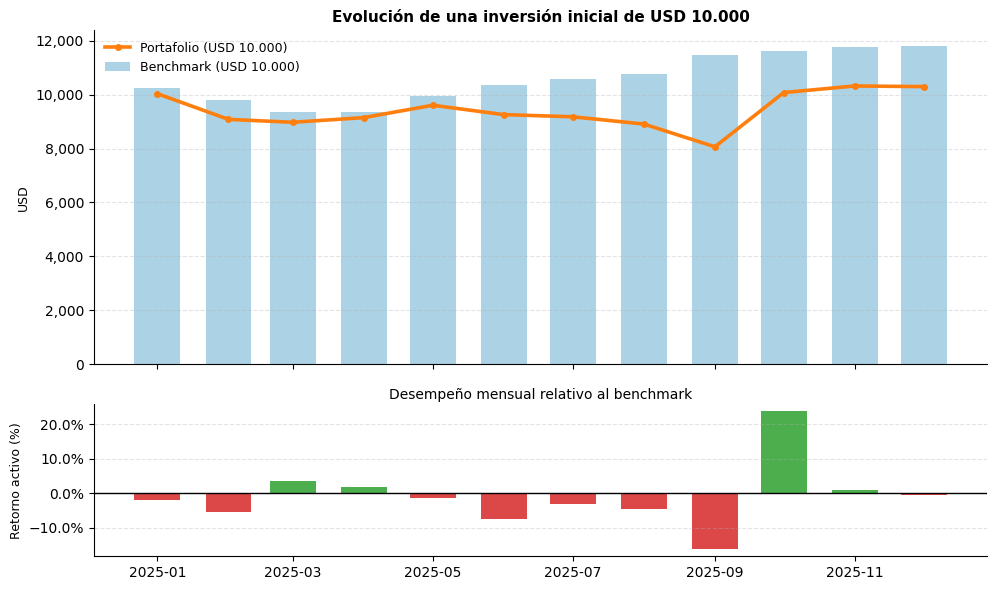

In [318]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np

# Si el índice es Period[M], convertir a timestamp
if isinstance(var.index, pd.PeriodIndex):
    x = var.index.to_timestamp()
else:
    x = var.index

# -----------------------------
# Colores
# -----------------------------
color_ganancia  = "#ff7f0e"   # naranja (portfolio)
color_benchmark = "#9ecae1"   # azul claro (benchmark)
color_positive  = "#2ca02c"   # verde
color_negative  = "#d62728"   # rojo

# -----------------------------
# Gráfico tipo factsheet
# -----------------------------
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(10, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1]}
)

# =============================
# Panel superior: Evolución del capital
# =============================
ax1.bar(
    x,
    var["indice_spy"],
    width=20,
    color=color_benchmark,
    alpha=0.85,
    label="Benchmark (USD 10.000)"
)

ax1.plot(
    x,
    var["indice_ganancia"],
    color=color_ganancia,
    linewidth=2.6,
    marker="o",
    markersize=4,
    label="Portafolio (USD 10.000)"
)

ax1.set_title(
    "Evolución de una inversión inicial de USD 10.000",
    fontsize=11,
    weight="bold",
    pad=6
)

ax1.set_ylabel("USD", fontsize=9)

ax1.yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda y, _: f"{int(y):,}")
)

ax1.grid(axis="y", linestyle="--", alpha=0.35)
ax1.grid(axis="x", visible=False)

ax1.legend(
    frameon=False,
    fontsize=9,
    loc="upper left"
)

ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# =============================
# Panel inferior: Retorno activo
# =============================
colors_active = np.where(
    var["active_return"] >= 0,
    color_positive,
    color_negative
)

ax2.bar(
    x,
    var["active_return"] * 100,
    width=20,
    color=colors_active,
    alpha=0.85
)

ax2.axhline(0, color="black", linewidth=1)

ax2.set_title(
    "Desempeño mensual relativo al benchmark",
    fontsize=10,
    pad=4
)

ax2.set_ylabel("Retorno activo (%)", fontsize=9)

ax2.yaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(axis="y", linestyle="--", alpha=0.35)
ax2.grid(axis="x", visible=False)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# =============================
# Ajustes finales
# =============================
plt.tight_layout()
plt.show()


In [ ]:
var['active_return'].mean()

np.float64(-0.00868584580058289)

In [ ]:
var['active_return'].std()

np.float64(0.09334324240414894)

In [ ]:
var['ganancia'].mean()

np.float64(0.00568947211573972)

In [ ]:
var['ganancia'].std()


np.float64(0.08820735764083677)

In [ ]:
var['SPY.BA'].mean()

np.float64(0.014375317916322608)

In [ ]:
var['SPY.BA'].std()


np.float64(0.03471882927437042)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Retornos mensuales
ret_port = var['ganancia']
ret_bench = var['SPY.BA']

metrics = pd.DataFrame({
    'Activo': ['Portafolio', 'Benchmark'],
    'Rendimiento': [
        ret_port.mean(),
        ret_bench.mean()
    ],
    'Volatilidad': [
        ret_port.std(),
        ret_bench.std()
    ]
})
metrics

,Activo,Rendimiento,Volatilidad
0,Portafolio,0.005689,0.088207
1,Benchmark,0.014375,0.034719


C:\Users\Admin\AppData\Local\Temp\ipykernel_10788\2686960768.py:90: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(frameon=False, fontsize=9, loc='upper left')


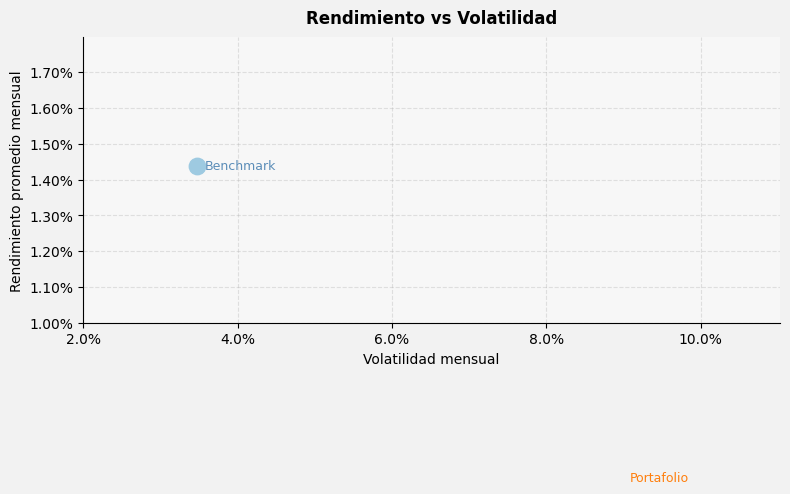

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# =======================
# Figura
# =======================
fig, ax = plt.subplots(figsize=(8, 6))

# Fondo profesional
fig.patch.set_facecolor('#f2f2f2')
ax.set_facecolor('#f7f7f7')

# =======================
# Extraer valores
# =======================
vol_port = metrics.loc[metrics['Activo'] == 'Portafolio', 'Volatilidad'].iloc[0]
ret_port = metrics.loc[metrics['Activo'] == 'Portafolio', 'Rendimiento'].iloc[0]

vol_bench = metrics.loc[metrics['Activo'] == 'Benchmark', 'Volatilidad'].iloc[0]
ret_bench = metrics.loc[metrics['Activo'] == 'Benchmark', 'Rendimiento'].iloc[0]

# =======================
# Scatter (SIN duplicación)
# =======================

# Benchmark
ax.scatter(
    vol_bench,
    ret_bench,
    s=140,
    marker='o',
    facecolor='#9ecae1')

# Portafolio
ax.scatter(
    vol_port,
    ret_port,
    s=180,
    marker='o',
    facecolor='#ff7f0e'
)

# =======================
# Etiquetas directas
# =======================
ax.text(
    vol_port * 1.03,
    ret_port,
    'Portafolio',
    fontsize=9,
    va='center',
    color='#ff7f0e'
)

ax.text(
    vol_bench * 1.03,
    ret_bench,
    'Benchmark',
    fontsize=9,
    va='center',
    color='#5b8db8'
)

# =======================
# Escala ampliada
# =======================
x_min = min(vol_port, vol_bench) * 0.8
x_max = max(vol_port, vol_bench) * 1.25
y_min = min(ret_port, ret_bench) * 0.8
y_max = max(ret_port, ret_bench) * 1.25

ax.set_xlim(0.02, x_max)
ax.set_ylim(0.01, y_max)

# =======================
# Estilo general
# =======================
ax.set_title('Rendimiento vs Volatilidad', fontsize=12, weight='bold', pad=10)
ax.set_xlabel('Volatilidad mensual', fontsize=10)
ax.set_ylabel('Rendimiento promedio mensual', fontsize=10)

ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))

ax.grid(axis='both', linestyle='--', linewidth=0.8, alpha=0.35)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

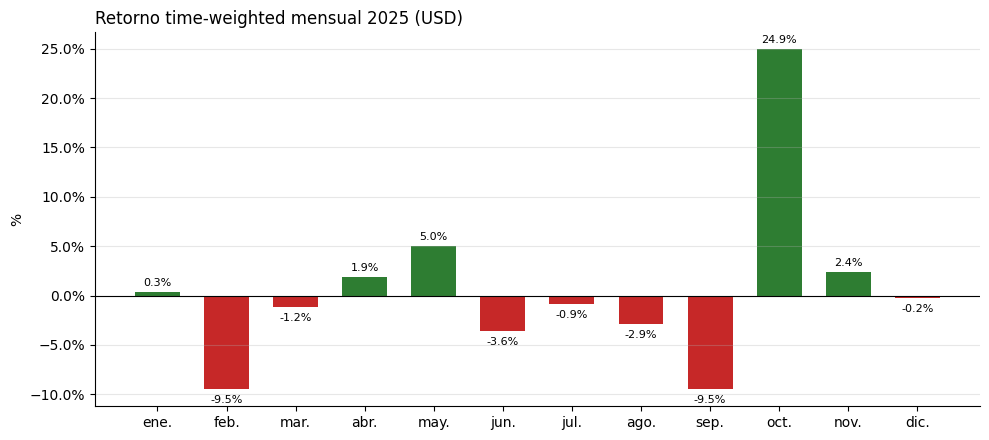

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

fig, ax = plt.subplots(figsize=(10, 4.5))

vals = twr * 100
colores = ['#2E7D32' if v >= 0 else '#C62828' for v in vals]

barras = ax.bar(range(len(vals)), vals, color=colores, width=0.65)

# etiquetas de valor sobre cada barra
for b, v in zip(barras, vals):
    ax.text(b.get_x() + b.get_width()/2,
            v + (0.6 if v >= 0 else -1.4),
            f'{v:.1f}%', ha='center', fontsize=8)

ax.axhline(0, color='black', linewidth=0.8)
ax.set_xticks(range(len(vals)))
ax.set_xticklabels(twr.index.strftime('%b'))
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Retorno time-weighted mensual 2025 (USD)', fontsize=12, loc='left')
ax.set_ylabel('%')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('twr_mensual_2025.png', dpi=200)
plt.show()

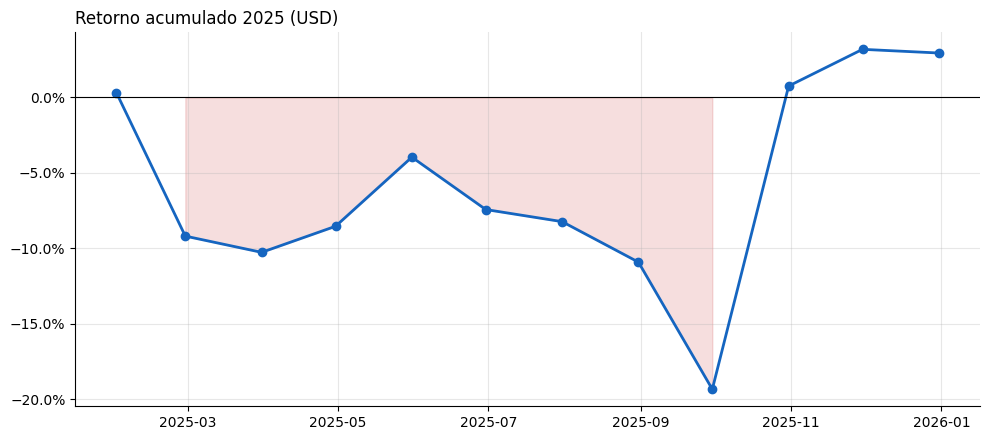

In [ ]:
acum = ((1 + twr).cumprod() - 1) * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(acum.index, acum.values, marker='o', color='#1565C0', linewidth=2)
ax.fill_between(acum.index, acum.values, 0,
                where=(acum.values < 0), color='#C62828', alpha=0.15)
ax.axhline(0, color='black', linewidth=0.8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('Retorno acumulado 2025 (USD)', fontsize=12, loc='left')
ax.spines[['top','right']].set_visible(False)
ax.grid(alpha=0.3)
plt.tight_layout()